In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

In [2]:
# Mount Google Drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# Update file paths to point to Google Drive location
train_sessions_path = '/content/drive/MyDrive/train_sessions.csv'
train_purchases_path = '/content/drive/MyDrive/train_purchases.csv'
item_features_path = '/content/drive/MyDrive/item_features.csv'
candidate_items_path = '/content/drive/MyDrive/candidate_items.csv'

In [5]:
# Function to read files from Google Drive
def read_file_from_drive(filepath):
    print(f"Reading file from: {filepath}")
    return pd.read_csv(filepath)

In [6]:
# Load datasets
train_sessions = read_file_from_drive(train_sessions_path)
train_purchases = read_file_from_drive(train_purchases_path)
item_features = read_file_from_drive(item_features_path)
candidate_items = read_file_from_drive(candidate_items_path)

Reading file from: /content/drive/MyDrive/train_sessions.csv
Reading file from: /content/drive/MyDrive/train_purchases.csv
Reading file from: /content/drive/MyDrive/item_features.csv
Reading file from: /content/drive/MyDrive/candidate_items.csv


In [7]:
# Merge train_sessions and train_purchases to analyze complete sessions
data = train_sessions.merge(train_purchases, on='session_id', suffixes=('_viewed', '_purchased'))


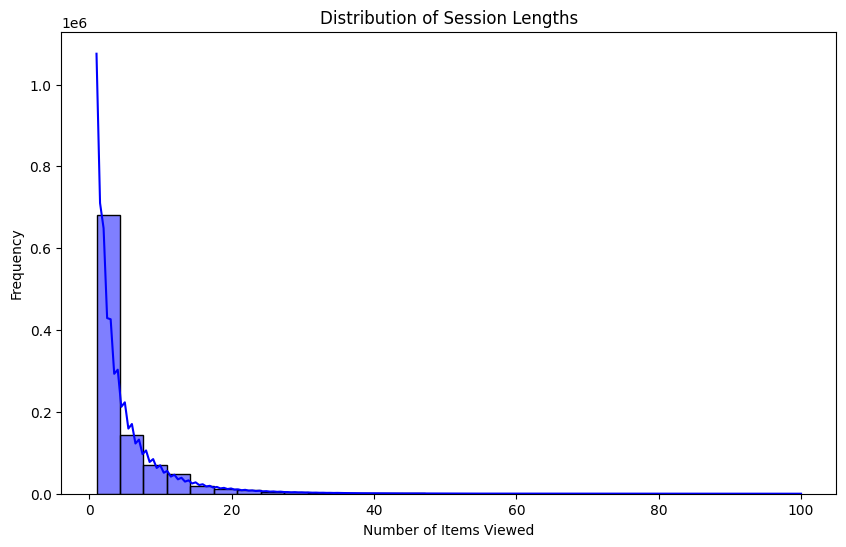

In [8]:
# 1. Session Activity Analysis
# Session length distribution
session_lengths = train_sessions.groupby('session_id').size()
plt.figure(figsize=(10, 6))
sns.histplot(session_lengths, bins=30, kde=True, color='blue')
plt.title('Distribution of Session Lengths')
plt.xlabel('Number of Items Viewed')
plt.ylabel('Frequency')
plt.show()

<ipython-input-16-87b7062c2656>:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='hour', data=train_sessions, palette='viridis')


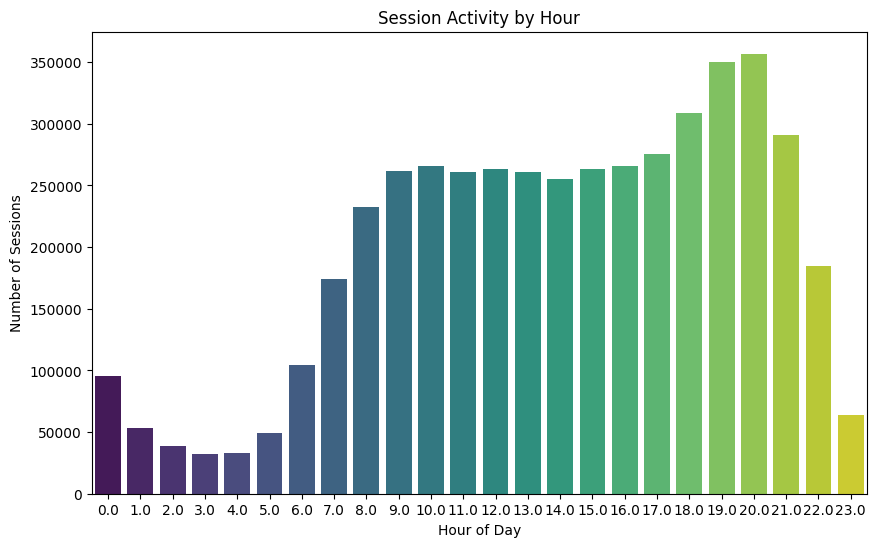

In [16]:
# Time-based session trends
train_sessions['date'] = pd.to_datetime(train_sessions['date'], errors='coerce')
train_sessions['hour'] = train_sessions['date'].dt.hour
plt.figure(figsize=(10, 6))
sns.countplot(x='hour', data=train_sessions, palette='viridis')
plt.title('Session Activity by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Sessions')
plt.show()

In [20]:
print(train_sessions.columns)


Index(['session_id', 'item_id', 'date', 'hour'], dtype='object')


In [19]:
# Frequency of purchases per hour
purchases = train_purchases.merge(train_sessions[['session_id', 'date']], on='session_id')
purchases['hour'] = pd.to_datetime(purchases['date'], errors='coerce').dt.hour
hourly_purchases = purchases.groupby('hour').size()
plt.figure(figsize=(10, 6))
sns.barplot(x=hourly_purchases.index, y=hourly_purchases.values, palette='coolwarm')
plt.title('Frequency of Purchases per Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Purchases')
plt.show()

KeyError: 'date'

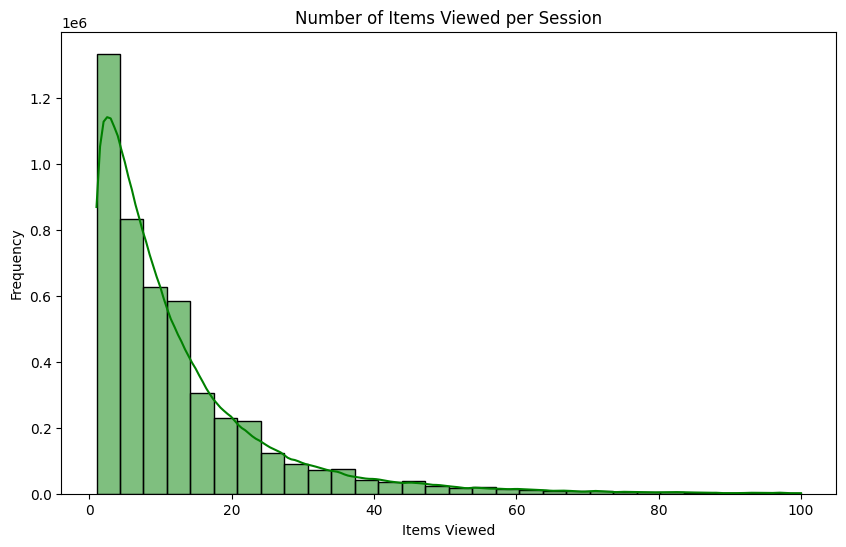

In [11]:
# Number of items viewed per session (extended dimensions)
data['num_items_viewed'] = data.groupby('session_id')['item_id_viewed'].transform('count')
plt.figure(figsize=(10, 6))
sns.histplot(data['num_items_viewed'], bins=30, kde=True, color='green')
plt.title('Number of Items Viewed per Session')
plt.xlabel('Items Viewed')
plt.ylabel('Frequency')
plt.show()

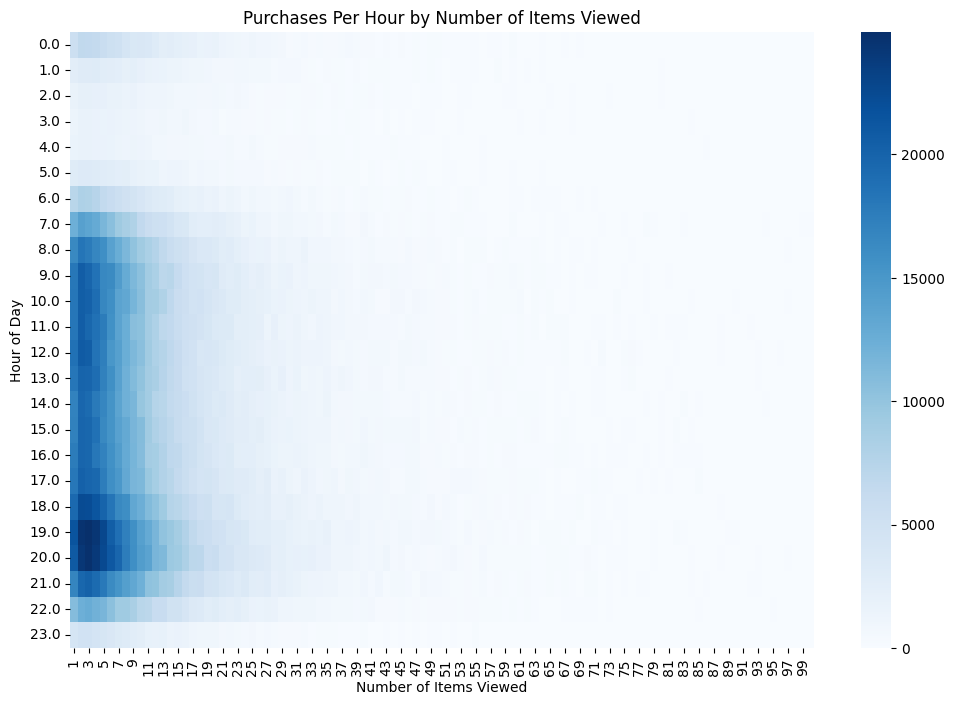

In [22]:
# Analysis of purchases per hour with session lengths
data['hour'] = pd.to_datetime(data['date_viewed'], errors='coerce').dt.hour
hour_session_purchases = data.groupby(['hour', 'num_items_viewed']).size().unstack(fill_value=0)
plt.figure(figsize=(12, 8))
sns.heatmap(hour_session_purchases, cmap='Blues', annot=False, cbar=True)
plt.title('Purchases Per Hour by Number of Items Viewed')
plt.xlabel('Number of Items Viewed')
plt.ylabel('Hour of Day')
plt.show()


<ipython-input-12-33dfdc15a9b3>:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=most_purchased.values, y=most_purchased.index, palette='coolwarm')


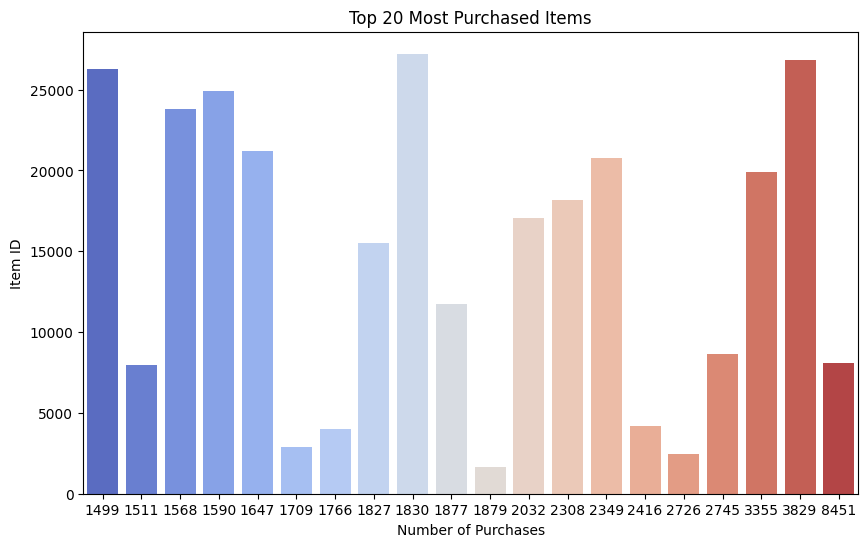

In [12]:
# 2. Purchase Trends
# Most purchased items
most_purchased = train_purchases['item_id'].value_counts().head(20)
plt.figure(figsize=(10, 6))
sns.barplot(x=most_purchased.values, y=most_purchased.index, palette='coolwarm')
plt.title('Top 20 Most Purchased Items')
plt.xlabel('Number of Purchases')
plt.ylabel('Item ID')
plt.show()

<ipython-input-13-6a3b5985f21f>:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feature_categories.index, y=feature_categories.values, palette='magma')


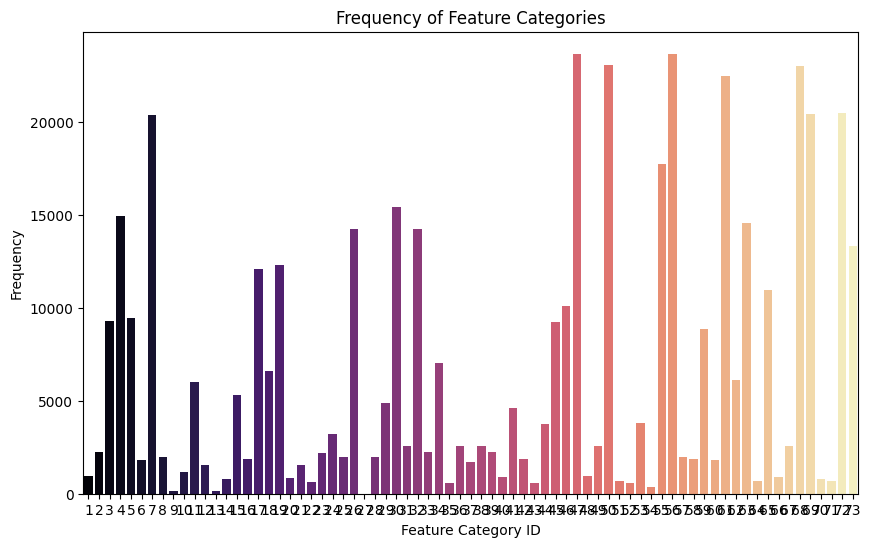

In [13]:
# 3. Item Features Analysis
# Frequency of feature categories
feature_categories = item_features['feature_category_id'].value_counts()
plt.figure(figsize=(10, 6))
sns.barplot(x=feature_categories.index, y=feature_categories.values, palette='magma')
plt.title('Frequency of Feature Categories')
plt.xlabel('Feature Category ID')
plt.ylabel('Frequency')
plt.show()

<ipython-input-14-1cc2cfca9da4>:4: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  candidate_vs_purchases['_merge'] = candidate_vs_purchases['_merge'].replace({'both': 'Purchased', 'left_only': 'Not Purchased'})
<ipython-input-14-1cc2cfca9da4>:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='_merge', data=candidate_vs_purchases, palette='Set2')


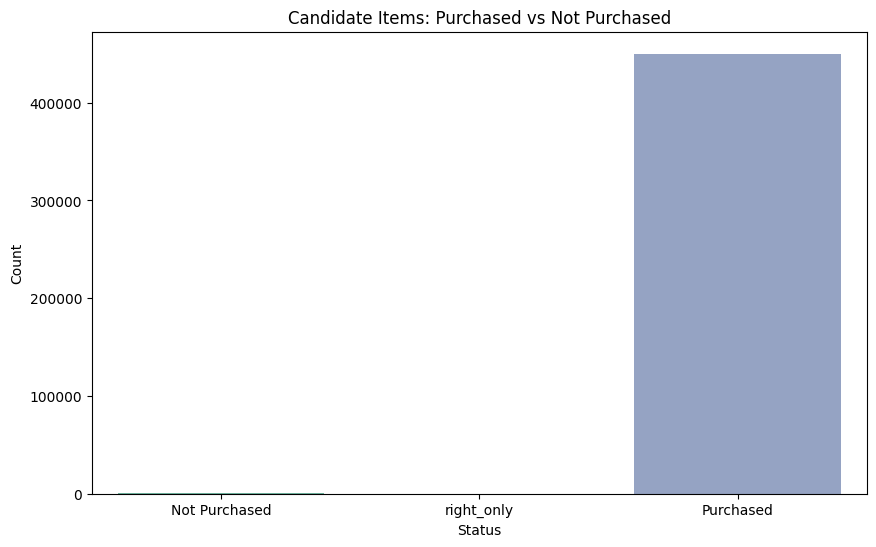

In [14]:
# 4. Candidate Items vs Purchased Items
# Candidate items vs purchases
candidate_vs_purchases = candidate_items.merge(train_purchases, on='item_id', how='left', indicator=True)
candidate_vs_purchases['_merge'] = candidate_vs_purchases['_merge'].replace({'both': 'Purchased', 'left_only': 'Not Purchased'})
plt.figure(figsize=(10, 6))
sns.countplot(x='_merge', data=candidate_vs_purchases, palette='Set2')
plt.title('Candidate Items: Purchased vs Not Purchased')
plt.xlabel('Status')
plt.ylabel('Count')
plt.show()

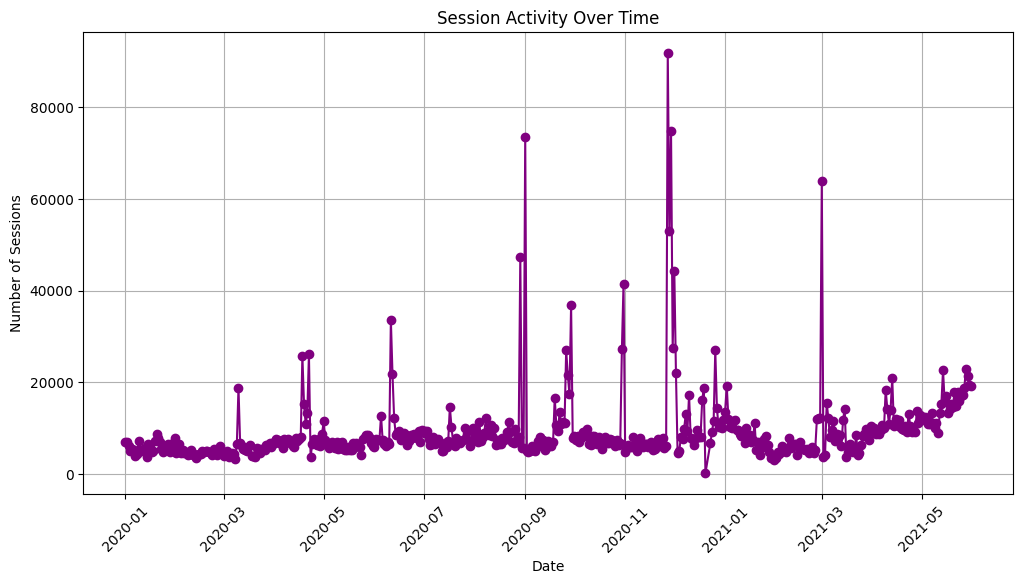

In [23]:
# Line plot of session activity over time
time_series = train_sessions.groupby(train_sessions['date'].dt.date).size()
plt.figure(figsize=(12, 6))
plt.plot(time_series.index, time_series.values, marker='o', color='purple')
plt.title('Session Activity Over Time')
plt.xlabel('Date')
plt.ylabel('Number of Sessions')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

In [25]:
# Pie chart of purchase distribution by hour
plt.figure(figsize=(8, 8))
hourly_purchases.plot.pie(autopct='%1.1f%%', startangle=140, colors=sns.color_palette('Set3'))
plt.title('Purchase Distribution by Hour')
plt.ylabel('')
plt.show()

NameError: name 'hourly_purchases' is not defined

<Figure size 800x800 with 0 Axes>

<ipython-input-26-6a3b5985f21f>:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feature_categories.index, y=feature_categories.values, palette='magma')


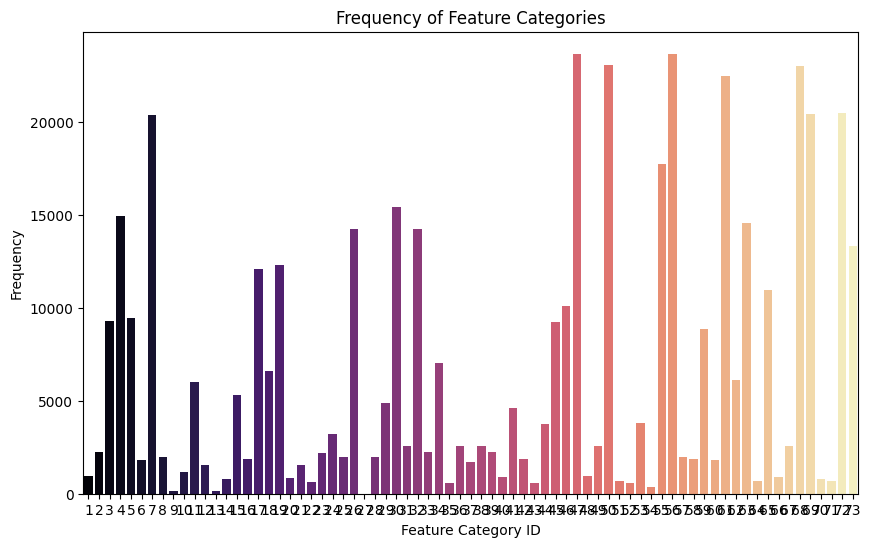

In [26]:
# 3. Item Features Analysis
# Frequency of feature categories
feature_categories = item_features['feature_category_id'].value_counts()
plt.figure(figsize=(10, 6))
sns.barplot(x=feature_categories.index, y=feature_categories.values, palette='magma')
plt.title('Frequency of Feature Categories')
plt.xlabel('Feature Category ID')
plt.ylabel('Frequency')
plt.show()

<ipython-input-27-1cc2cfca9da4>:4: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  candidate_vs_purchases['_merge'] = candidate_vs_purchases['_merge'].replace({'both': 'Purchased', 'left_only': 'Not Purchased'})
<ipython-input-27-1cc2cfca9da4>:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='_merge', data=candidate_vs_purchases, palette='Set2')


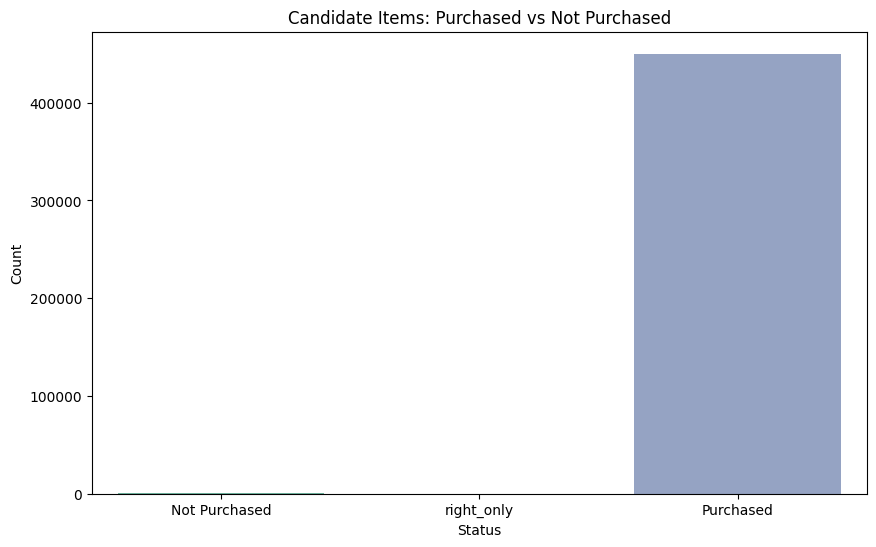

In [27]:
# 4. Candidate Items vs Purchased Items
# Candidate items vs purchases
candidate_vs_purchases = candidate_items.merge(train_purchases, on='item_id', how='left', indicator=True)
candidate_vs_purchases['_merge'] = candidate_vs_purchases['_merge'].replace({'both': 'Purchased', 'left_only': 'Not Purchased'})
plt.figure(figsize=(10, 6))
sns.countplot(x='_merge', data=candidate_vs_purchases, palette='Set2')
plt.title('Candidate Items: Purchased vs Not Purchased')
plt.xlabel('Status')
plt.ylabel('Count')
plt.show()

<ipython-input-30-33dfdc15a9b3>:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=most_purchased.values, y=most_purchased.index, palette='coolwarm')


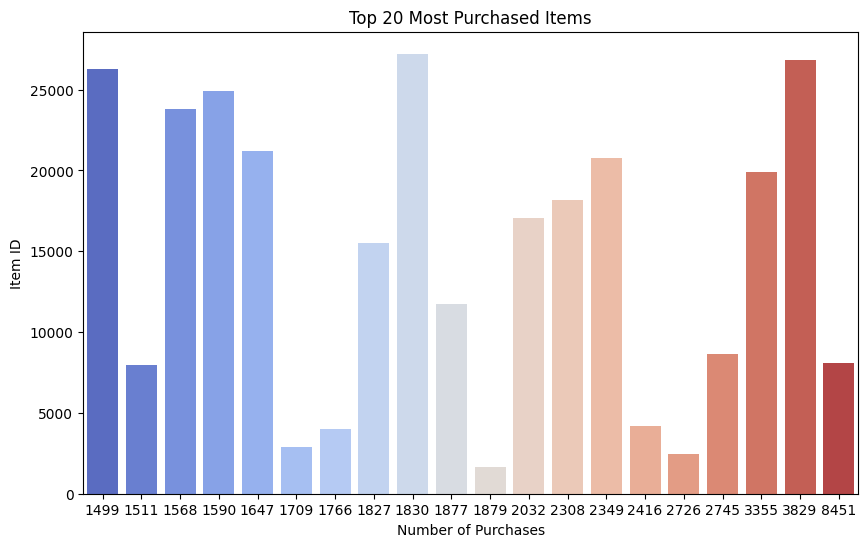

In [30]:
# 2. Purchase Trends
# Most purchased items
most_purchased = train_purchases['item_id'].value_counts().head(20)
plt.figure(figsize=(10, 6))
sns.barplot(x=most_purchased.values, y=most_purchased.index, palette='coolwarm')
plt.title('Top 20 Most Purchased Items')
plt.xlabel('Number of Purchases')
plt.ylabel('Item ID')
plt.show()

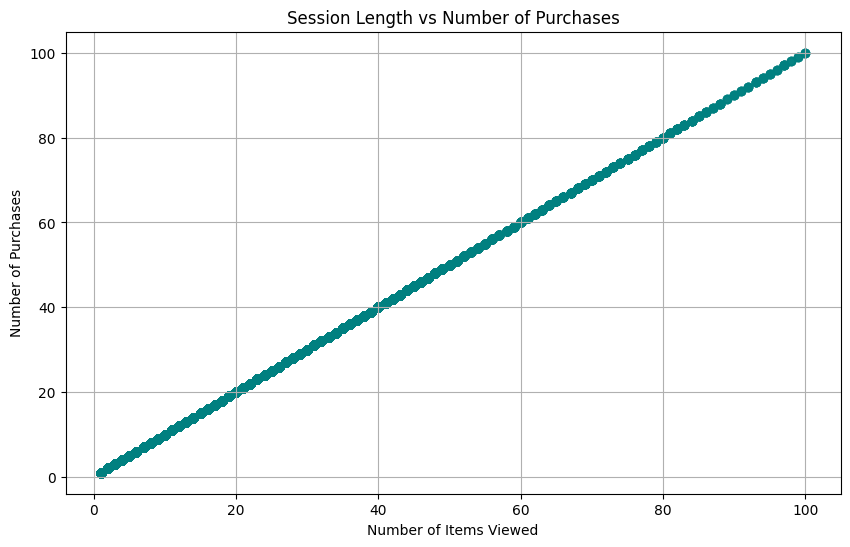

In [28]:
# Scatter plot: session length vs purchases
session_purchase_data = data.groupby('session_id').agg({'item_id_viewed': 'count', 'item_id_purchased': 'count'})
plt.figure(figsize=(10, 6))
plt.scatter(session_purchase_data['item_id_viewed'], session_purchase_data['item_id_purchased'], alpha=0.5, color='teal')
plt.title('Session Length vs Number of Purchases')
plt.xlabel('Number of Items Viewed')
plt.ylabel('Number of Purchases')
plt.grid(True)
plt.show()